# PolyGen | Text-to-3D Generation

Create a 3D model from **a text prompt** or **an uploaded image**. SDXL-Turbo generates the reference image; Hunyuan3D-2mini generates the 3D geometry. Preview and export a GLB/OBJ for the PolyGen React viewer.

**Google Colab + T4 GPU:** run cells from top to bottom. Start with `INPUT_MODE = 'text'` in Section 3. The exported GLB has a basic solid-color material; image-based UV texturing is planned for Week 2.


## 1. Check GPU and configure paths


In [ ]:
import os, sys, platform
from pathlib import Path
import torch

ROOT = Path('/content/polygen')
INPUTS = ROOT / 'inputs'
OUTPUTS = ROOT / 'outputs'
for folder in (ROOT, INPUTS, OUTPUTS):
    folder.mkdir(parents=True, exist_ok=True)

if not torch.cuda.is_available():
    raise RuntimeError('GPU not detected. Colab: Runtime > Change runtime type > T4 GPU.')

print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('GPU:', torch.cuda.get_device_name(0))
print('CUDA:', torch.version.cuda)
print('Total GPU memory: %.1f GiB' % (torch.cuda.get_device_properties(0).total_memory / 2**30))
print('Project folder:', ROOT)

Python: 3.13.16
PyTorch: 2.14.1+cu130
GPU: Tesla T4
CUDA: 13.0
Total GPU memory: 14.6 GiB
Project folder: /content/polygen


## 2. Install Hunyuan3D dependencies

Run once per new Colab runtime. If Transformers was already imported, restart the session afterward and rerun from Section 1.


In [ ]:
import subprocess, sys, importlib
from pathlib import Path

def pip_install(*specs):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *specs], check=True)

pip_install(
    'transformers>=4.48,<5',
    'diffusers>=0.32,<1',
    'accelerate>=1.0',
    'safetensors', 'huggingface_hub', 'scipy',
    'einops', 'omegaconf', 'trimesh>=4',
    'numpy', 'Pillow', 'scikit-image', 'pymeshlab',
    'pygltflib', 'xatlas', 'opencv-python',
    'rembg', 'onnxruntime', 'plotly',
)

REPO = Path('/content/Hunyuan3D-2')
if not (REPO / 'hy3dgen' / 'shapegen' / '__init__.py').is_file():
    if REPO.exists():
        raise RuntimeError(f'Incomplete repository at {REPO}. Rename/delete it manually, then rerun.')
    subprocess.run(['git', 'clone', '--depth', '1',
                    'https://github.com/Tencent-Hunyuan/Hunyuan3D-2.git', str(REPO)], check=True)

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', '-e', str(REPO)], check=True)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
importlib.invalidate_caches()
print('Hunyuan shape packages and repository installed.')
print('If Transformers was already loaded in memory before this cell, restart the session now.')

Hunyuan shape packages and repository installed.
If Transformers was already loaded in memory before this cell, restart the session now.


In [ ]:
import importlib.metadata as meta
from pathlib import Path
import sys, torch

assert (Path('/content/Hunyuan3D-2')/'hy3dgen'/'shapegen'/'__init__.py').is_file()
if '/content/Hunyuan3D-2' not in sys.path:
    sys.path.insert(0, '/content/Hunyuan3D-2')

from hy3dgen.shapegen import Hunyuan3DDiTFlowMatchingPipeline
import trimesh
import transformers

major, minor = [int(x) for x in transformers.__version__.split('.')[:2]]
assert major == 4 and minor >= 48, (f'Loaded Transformers {transformers.__version__}. '
       'Restart the Colab session and run from Section 1.')
print('Shape generator import: OK')
print('Transformers:', transformers.__version__)
print('trimesh:', trimesh.__version__)
print('GPU:', torch.cuda.get_device_name(0))

Shape generator import: OK
Transformers: 4.57.6
trimesh: 5.2.2
GPU: Tesla T4


## 3. Select a text prompt or uploaded image

Choose `INPUT_MODE = 'text'` for automatic prompt → image → 3D, or `'upload'` to reuse the earlier image-to-3D workflow. Keep the prompt focused on **one complete object** and describe its shape and color.


In [ ]:
import re

INPUT_MODE = 'text'
OBJECT_PROMPT = 'a blue glazed ceramic coffee mug with a round handle'
IMAGE_SEED = 12345
IMAGE_STEPS = 4
TEXT_IMAGE_MODEL_ID = 'stabilityai/sdxl-turbo'

if INPUT_MODE not in ('text', 'upload'):
    raise ValueError("INPUT_MODE must be 'text' or 'upload'.")
if INPUT_MODE == 'text' and not OBJECT_PROMPT.strip():
    raise ValueError('Provide a description in OBJECT_PROMPT.')

print('Input mode:', INPUT_MODE)
if INPUT_MODE == 'text':
    print('Object:', OBJECT_PROMPT)


Input mode: text
Object: a blue glazed ceramic coffee mug with a round handle


## 4. Generate a reference image from text

Runs only when `INPUT_MODE = 'text'`. SDXL-Turbo generates a centered product-style reference at 512×512. Inspect the result before proceeding; if the shape is unclear, adjust the prompt or seed and rerun this cell. The image model is then unloaded to leave GPU memory for Hunyuan3D. SDXL-Turbo is subject to its [model license](https://huggingface.co/stabilityai/sdxl-turbo).


Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading text-to-image model: stabilityai/sdxl-turbo


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/685 [00:00<?, ?B/s]

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

scheduler_config.json:   0%|          | 0.00/459 [00:00<?, ?B/s]

... (16 outputs left out)

Generating reference image...


  0%|          | 0/4 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Generated image: /content/polygen/inputs/reference_image.png


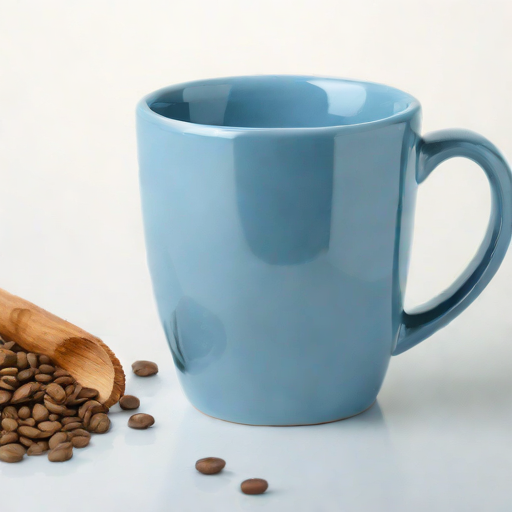

In [ ]:
if INPUT_MODE == 'text':
    import gc
    import torch
    from PIL import Image
    from IPython.display import display
    from diffusers import AutoPipelineForText2Image

    styled_prompt = (
        OBJECT_PROMPT.strip().rstrip('. ')
        + ', one complete object, centered, three-quarter product view, '
        + 'clean white studio background, sharp focus, full object visible, '
        + 'no people, no text, no watermark, no extra objects'
    )
    image_pipeline = None
    try:
        print('Loading text-to-image model:', TEXT_IMAGE_MODEL_ID)
        image_pipeline = AutoPipelineForText2Image.from_pretrained(
            TEXT_IMAGE_MODEL_ID,
            torch_dtype=torch.float16,
            variant='fp16',
            use_safetensors=True,
        )
        image_pipeline = image_pipeline.to('cuda')
        image_pipeline.enable_vae_slicing()
        generator = torch.Generator(device='cuda').manual_seed(IMAGE_SEED)
        print('Generating reference image...')
        with torch.inference_mode():
            generated_reference = image_pipeline(
                prompt=styled_prompt,
                num_inference_steps=IMAGE_STEPS,
                guidance_scale=0.0,
                width=512,
                height=512,
                generator=generator,
            ).images[0]

        image_path = INPUTS / 'reference_image.png'
        generated_reference.convert('RGB').save(image_path)
        ASSET_NAME = re.sub(r'[^a-z0-9]+', '_', OBJECT_PROMPT.lower()).strip('_')[:45] or 'asset'
        filename = 'reference_image.png'
        INPUT_SOURCE = 'text'
        print('Generated image:', image_path)
        display(generated_reference)
    finally:
        del image_pipeline
        gc.collect()
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()
    if not (INPUTS / 'reference_image.png').is_file():
        raise RuntimeError('Text-to-image generation did not produce an image.')
else:
    print('Upload mode selected; skip this step and use Section 5.')


## 5. Upload a reference image (optional)

Only runs when `INPUT_MODE = 'upload'`. Otherwise, keep the image generated in Section 4.


In [ ]:
if INPUT_MODE == 'upload':
    from google.colab import files
    from PIL import Image, ImageOps
    from IPython.display import display
    from io import BytesIO
    from pathlib import Path
    import re

    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError('No image selected.')
    filename, file_bytes = next(iter(uploaded.items()))
    source = ImageOps.exif_transpose(Image.open(BytesIO(file_bytes))).convert('RGBA')
    if source.width < 128 or source.height < 128:
        raise ValueError('Image too small. Use at least 512px when possible.')
    ASSET_NAME = re.sub(r'[^a-z0-9]+', '_', Path(filename).stem.lower()).strip('_') or 'asset'
    source.save(INPUTS / 'reference_image.png')
    INPUT_SOURCE = 'upload'
    print('Uploaded:', filename, '| Size:', source.size, '| Asset:', ASSET_NAME)
    display(source)
else:
    print('Using the AI-generated reference image from Section 4.')


Using the AI-generated reference image from Section 4.


## 6. Remove the background

Review the resulting mask. Set `REMOVE_BACKGROUND = False` only when the image already has transparency.


/usr/local/lib/python3.13/dist-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


Removing background with isnet-general-use (first use downloads its ONNX weights)...


  0%|                                               | 0.00/179M [00:00<?, ?B/s]

RGBA image: RGBA (512, 512)
RGB image: RGB (512, 512)
Foreground bbox (original pixels): (134, 73, 512, 427)


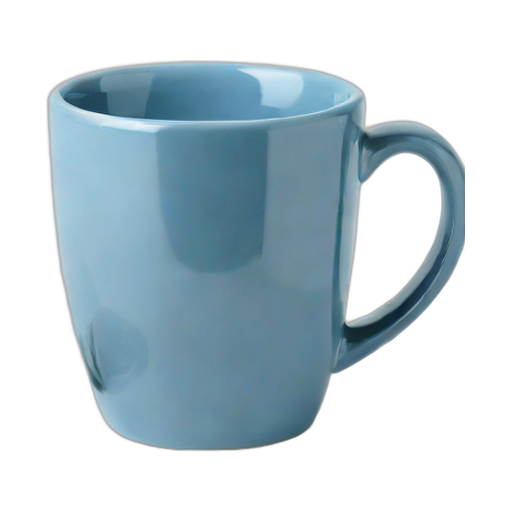

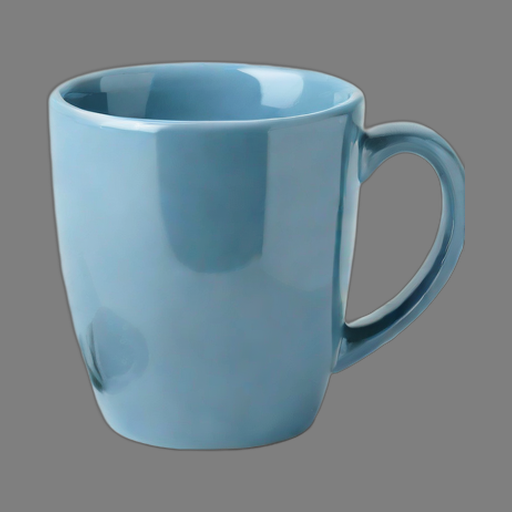

In [ ]:
from PIL import Image, ImageOps
from rembg import remove, new_session
from IPython.display import display
import numpy as np

REMOVE_BACKGROUND = True
FOREGROUND_FRACTION = 0.82
TARGET_SIZE = 512

raw = Image.open(INPUTS / 'reference_image.png').convert('RGBA')
original_alpha = np.asarray(raw.getchannel('A'))
transparent_source = bool((original_alpha < 250).any())

if transparent_source:
    isolated = raw
    print('Existing transparency detected; retaining original alpha.')
elif REMOVE_BACKGROUND:
    print('Removing background with isnet-general-use (first use downloads its ONNX weights)...')
    session = new_session('isnet-general-use')
    isolated = remove(raw, session=session).convert('RGBA')
else:
    raise RuntimeError('Source has no transparency. Enable REMOVE_BACKGROUND or upload a PNG with transparent background.')

alpha = np.asarray(isolated.getchannel('A'))
ys, xs = np.where(alpha > 16)
if len(xs) < 250:
    raise ValueError('Object mask is empty or unusable. Check reference image or background removal.')

bbox = (int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1)
cropped = isolated.crop(bbox)
content_target = int(TARGET_SIZE * FOREGROUND_FRACTION)
scale = min(content_target / cropped.width, content_target / cropped.height)
newsize = (max(1, round(cropped.width * scale)), max(1, round(cropped.height * scale)))
object_layer = cropped.resize(newsize, Image.Resampling.LANCZOS)
prepared_rgba = Image.new('RGBA', (TARGET_SIZE, TARGET_SIZE), (0, 0, 0, 0))
prepared_rgba.alpha_composite(object_layer, ((TARGET_SIZE-newsize[0])//2, (TARGET_SIZE-newsize[1])//2))
prepared_rgba.save(INPUTS/'foreground_rgba.png')

gray = Image.new('RGBA', prepared_rgba.size, (127, 127, 127, 255))
prepared_rgb = Image.alpha_composite(gray, prepared_rgba).convert('RGB')
prepared_rgb.save(INPUTS/'foreground_rgb.png')

print('RGBA image:', prepared_rgba.mode, prepared_rgba.size)
print('RGB image:', prepared_rgb.mode, prepared_rgb.size)
print('Foreground bbox (original pixels):', bbox)
display(prepared_rgba, prepared_rgb)

## 7. Load Hunyuan3D-2mini


In [ ]:
from hy3dgen.shapegen import Hunyuan3DDiTFlowMatchingPipeline
import torch


MODEL_ID = 'tencent/Hunyuan3D-2mini'
MODEL_SUBFOLDER = 'hunyuan3d-dit-v2-mini'

print('Loading Hunyuan3D-2mini shape model...')
try:
    pipeline = Hunyuan3DDiTFlowMatchingPipeline.from_pretrained(
        MODEL_ID,
        subfolder=MODEL_SUBFOLDER,
        variant='fp16',
        use_safetensors=True,
        device='cuda',
    )
except Exception as exc:
    raise RuntimeError('Unable to load Hunyuan3D-2mini. Check Transformers/Diffusers '
                       'compatibility, Hugging Face access and GPU memory. '
                       'Use the separate TripoSR fallback notebook if needed.') from exc

print('Model loaded successfully on CUDA.')

2026-11-22 16:51:02,261 - hy3dgen.shapgen - INFO - Try to load model from local path: /root/.cache/hy3dgen/tencent/Hunyuan3D-2mini/hunyuan3d-dit-v2-mini
INFO:hy3dgen.shapgen:Try to load model from local path: /root/.cache/hy3dgen/tencent/Hunyuan3D-2mini/hunyuan3d-dit-v2-mini
2026-11-22 16:51:02,264 - hy3dgen.shapgen - INFO - Model path not exists, try to download from huggingface
INFO:hy3dgen.shapgen:Model path not exists, try to download from huggingface


Loading Hunyuan3D-2mini shape model...


Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

config.yaml: 0.00B [00:00, ?B/s]

hunyuan3d-dit-v2-mini/model.fp16.safeten(…):   0%|          | 0.00/3.82G [00:00<?, ?B/s]

hunyuan3d-dit-v2-mini/model.fp16.ckpt:   0%|          | 0.00/3.82G [00:00<?, ?B/s]

2026-11-22 16:54:44,254 - hy3dgen.shapgen - INFO - Loading model from /root/.cache/huggingface/hub/models--tencent--Hunyuan3D-2mini/snapshots/f90a0f7df7d5e6f71109cf333f6a95a0ae3194a6/hunyuan3d-dit-v2-mini/model.fp16.safetensors
INFO:hy3dgen.shapgen:Loading model from /root/.cache/huggingface/hub/models--tencent--Hunyuan3D-2mini/snapshots/f90a0f7df7d5e6f71109cf333f6a95a0ae3194a6/hunyuan3d-dit-v2-mini/model.fp16.safetensors


PointCrossAttentionEncoder INFO: pc_sharpedge_size is given, using pc_size=5120, pc_sharpedge_size=5120
Model loaded successfully on CUDA.


## 8. Generate the 3D mesh

Choose `QUALITY = 'balanced'` or `'high'`. Use balanced if GPU memory is limited.


In [ ]:
from datetime import datetime, timezone
from pathlib import Path
import torch, time, gc
import trimesh

QUALITY = 'balanced'
SEED = 12345
PRESETS = {
    'balanced': {'num_inference_steps': 30, 'octree_resolution': 300, 'num_chunks': 12000},
    'high':     {'num_inference_steps': 50, 'octree_resolution': 380, 'num_chunks': 12000},
}
params = PRESETS[QUALITY]

RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')
RUN_DIR = OUTPUTS / f'{ASSET_NAME}_{RUN_ID}'
RUN_DIR.mkdir(parents=True, exist_ok=True)

torch.cuda.empty_cache()
start = time.perf_counter()
print('Generating:', ASSET_NAME, '| quality:', QUALITY, '| settings:', params)
try:
    with torch.inference_mode():
        shapes = pipeline(
            image=prepared_rgba,
            generator=torch.manual_seed(SEED),
            output_type='trimesh',
            **params,
        )
except torch.cuda.OutOfMemoryError as exc:
    torch.cuda.empty_cache()
    raise RuntimeError('GPU ran out of memory. Rerun this cell with QUALITY="balanced"; '
                       'close other GPU models and restart only if necessary.') from exc

mesh_raw = shapes[0]
if not isinstance(mesh_raw, trimesh.Trimesh):
    raise TypeError(f'Expected trimesh.Trimesh, got {type(mesh_raw)!r}')
if len(mesh_raw.vertices) == 0 or len(mesh_raw.faces) == 0:
    raise ValueError('The model returned an empty mesh. Try another image.')

RAW_PATH = RUN_DIR/'model_raw.glb'
mesh_raw.export(RAW_PATH)
GENERATION_SECONDS = time.perf_counter() - start
print('Success! Vertices:', len(mesh_raw.vertices), '| Faces:', len(mesh_raw.faces))
print('Time: %.1f sec' % GENERATION_SECONDS)
print('Raw geometry:', RAW_PATH)

Generating: a_blue_glazed_ceramic_coffee_mug_with_a_round | quality: balanced | settings: {'num_inference_steps': 30, 'octree_resolution': 300, 'num_chunks': 12000}


Volume Decoding: 100%|██████████| 2273/2273 [00:40<00:00, 56.70it/s]


Success! Vertices: 517027 | Faces: 1034060
Time: 49.5 sec
Raw geometry: /content/polygen/outputs/a_blue_glazed_ceramic_coffee_mug_with_a_round_20261122_165535/model_raw.glb


## 9. Check generated geometry


In [ ]:
import numpy as np

extents = mesh_raw.bounding_box.extents
components = mesh_raw.split(only_watertight=False)
print('Vertices:', len(mesh_raw.vertices))
print('Triangles:', len(mesh_raw.faces))
print('Bounds (x,y,z):', np.round(extents, 3).tolist())
print('Connected components:', len(components))
print('Watertight:', mesh_raw.is_watertight)
print('Valid geometry:', bool(mesh_raw.is_volume) if mesh_raw.is_watertight else 'not a closed volume')
print('Nonfinite vertices:', int((~np.isfinite(mesh_raw.vertices)).any(axis=1).sum()))

Vertices: 517027
Triangles: 1034060
Bounds (x,y,z): [2.0, 1.732, 1.629]
Connected components: 6
Watertight: False
Valid geometry: not a closed volume
Nonfinite vertices: 0


## 10. Normalize and orient the model


In [ ]:
import trimesh, numpy as np
from scipy.spatial.transform import Rotation

ROTATION_X_DEG = 0.0
ROTATION_Y_DEG = 0.0
ROTATION_Z_DEG = 0.0
NORMALIZED_MAX_SIZE = 3.0

mesh_final = mesh_raw.copy()
if not np.isfinite(mesh_final.vertices).all():
    raise ValueError('Mesh has invalid vertex coordinates.')

rotation = Rotation.from_euler('xyz', [ROTATION_X_DEG, ROTATION_Y_DEG, ROTATION_Z_DEG], degrees=True)
mesh_final.apply_transform(np.block([
    [rotation.as_matrix(), np.zeros((3, 1))],
    [np.zeros((1, 3)), np.ones((1, 1))]
]))

bounds = mesh_final.bounds
mesh_final.apply_translation(-mesh_final.bounding_box.centroid)
max_extent = float(mesh_final.bounding_box.extents.max())
if max_extent <= 1e-8:
    raise ValueError('Mesh bounds are degenerate.')
mesh_final.apply_scale(NORMALIZED_MAX_SIZE / max_extent)
mesh_final.apply_translation([0, -float(mesh_final.bounds[0,1]), 0])

print('Normalized geometry:', mesh_final.bounding_box.extents.round(3).tolist())
print('Ground position:', round(float(mesh_final.bounds[0,1]), 6))

Normalized geometry: [3.0, 2.598, 2.444]
Ground position: 0.0


## 11. Set a basic PBR material

`MATERIAL_HEX` controls the solid color. Image-based textures will be added later.


In [ ]:
from trimesh.visual.material import PBRMaterial
from trimesh.visual import TextureVisuals

MATERIAL_HEX = '#C8283F'
METALLIC = 0.02
ROUGHNESS = 0.32

def rgba_from_hex(value):
    value = value.lstrip('#')
    if len(value) != 6:
        raise ValueError('Use a six-digit hex color such as #C8283F')
    return [int(value[i:i+2], 16) for i in (0, 2, 4)] + [255]

mesh_final.visual = TextureVisuals(material=PBRMaterial(
    baseColorFactor=rgba_from_hex(MATERIAL_HEX),
    metallicFactor=METALLIC,
    roughnessFactor=ROUGHNESS,
    doubleSided=True,
))
print('PBR material applied:', MATERIAL_HEX, '| metallic:', METALLIC, '| roughness:', ROUGHNESS)

PBR material applied: #C8283F | metallic: 0.02 | roughness: 0.32


## 12. Preview the model


In [ ]:
import plotly.graph_objects as go
import numpy as np
from IPython.display import display

MAX_PREVIEW_FACES = 20000
faces = np.asarray(mesh_final.faces)
if len(faces) > MAX_PREVIEW_FACES:
    selection = np.linspace(0, len(faces)-1, MAX_PREVIEW_FACES, dtype=int)
    faces = faces[selection]
unique, inverse = np.unique(faces.ravel(), return_inverse=True)
compact_v = np.asarray(mesh_final.vertices)[unique]
compact_f = inverse.reshape(-1, 3)

fig = go.Figure(data=[go.Mesh3d(
    x=compact_v[:,0], y=compact_v[:,1], z=compact_v[:,2],
    i=compact_f[:,0], j=compact_f[:,1], k=compact_f[:,2],
    color=MATERIAL_HEX, opacity=1.0, flatshading=False,
    lighting={'ambient':0.55, 'diffuse':0.8, 'specular':0.4, 'roughness':0.5},
    lightposition={'x':4,'y':8,'z':5},
)])
fig.update_layout(
    title=f'PolyGen | {ASSET_NAME} | {QUALITY}',
    scene={'aspectmode':'data','xaxis':{'visible':False},'yaxis':{'visible':False},'zaxis':{'visible':False},
           'camera':{'eye':{'x':1.9,'y':1.25,'z':1.9},'up':{'x':0,'y':1,'z':0}}},
    margin={'l':0,'r':0,'t':45,'b':0},
    height=600,
)
fig.show()
PREVIEW_PATH = RUN_DIR/'interactive_preview.html'
fig.write_html(str(PREVIEW_PATH), include_plotlyjs=True, full_html=True)
print('Preview saved:', PREVIEW_PATH)

Preview saved: /content/polygen/outputs/a_blue_glazed_ceramic_coffee_mug_with_a_round_20261122_165535/interactive_preview.html


## 13. Export GLB, OBJ, and ZIP


In [ ]:
import json, zipfile, shutil
from pathlib import Path

GLB_PATH = RUN_DIR/'polygen_model.glb'
OBJ_PATH = RUN_DIR/'polygen_model.obj'
REPORT_PATH = RUN_DIR/'generation_report.json'
ZIP_PATH = RUN_DIR/'polygen_asset_bundle.zip'

mesh_final.export(str(GLB_PATH))
mesh_final.export(str(OBJ_PATH))

check = trimesh.load(GLB_PATH, force='scene')
assert len(check.geometry) > 0, 'Exported GLB has no geometry.'

report = {
    'project':'PolyGen', 'stage':'text_to_shape' if INPUT_SOURCE == 'text' else 'image_to_shape',
    'input_source':INPUT_SOURCE,
    'prompt':OBJECT_PROMPT if INPUT_SOURCE == 'text' else None,
    'text_to_image_model':TEXT_IMAGE_MODEL_ID if INPUT_SOURCE == 'text' else None,
    'image_seed':IMAGE_SEED if INPUT_SOURCE == 'text' else None,
    'image_steps':IMAGE_STEPS if INPUT_SOURCE == 'text' else None,
    'engine':'Hunyuan3D-2mini', 'model':MODEL_ID,
    'input_filename':filename, 'seed':SEED, 'quality':QUALITY,
    'model_settings':params, 'seconds':round(GENERATION_SECONDS,2),
    'vertices':int(len(mesh_final.vertices)), 'faces':int(len(mesh_final.faces)),
    'components':int(len(components)), 'watertight':bool(mesh_raw.is_watertight),
    'bounds_xyz':np.round(mesh_final.bounding_box.extents,4).tolist(),
    'visual_material':{'base_color':MATERIAL_HEX,'metallic':METALLIC,'roughness':ROUGHNESS},
    'texture_note':'Solid material only; no UV photorealistic texture generated.',
}
REPORT_PATH.write_text(json.dumps(report, indent=2), encoding='utf-8')

with zipfile.ZipFile(ZIP_PATH, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for path in (RAW_PATH, GLB_PATH, OBJ_PATH, REPORT_PATH, PREVIEW_PATH,
                 INPUTS/'reference_image.png', INPUTS/'foreground_rgba.png', INPUTS/'foreground_rgb.png'):
        zf.write(path, arcname=('inputs/' + path.name if path.parent==INPUTS else path.name))

for p in (GLB_PATH, OBJ_PATH, REPORT_PATH, ZIP_PATH):
    print(f'{p.name}: {p.stat().st_size/1024**2:.2f} MB')
print('Output directory:', RUN_DIR)

polygen_model.glb: 17.75 MB
polygen_model.obj: 39.82 MB
generation_report.json: 0.00 MB
polygen_asset_bundle.zip: 24.69 MB
Output directory: /content/polygen/outputs/a_blue_glazed_ceramic_coffee_mug_with_a_round_20261122_165535


## 14. Download the result


In [ ]:
from google.colab import files
files.download(str(ZIP_PATH))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Optional Google Drive backup

Set `BACKUP_TO_DRIVE = True` to save files beyond the temporary Colab runtime.


In [ ]:
BACKUP_TO_DRIVE = False
if BACKUP_TO_DRIVE:
    from google.colab import drive
    import shutil
    drive.mount('/content/drive')
    destination = Path('/content/drive/MyDrive/PolyGen/3d_generation') / RUN_DIR.name
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(RUN_DIR, destination, dirs_exist_ok=True)
    print('Saved to:', destination)
else:
    print('Drive backup disabled. Keep your downloaded ZIP.')

Drive backup disabled. Keep your downloaded ZIP.


## 16. Display the GLB in React

Extract `polygen_model.glb` from the ZIP into `frontend/public/models/polygen_model.glb`. Your existing `ModelViewer.jsx` loads it using `useGLTF` or `GLTFLoader`. The image-generation color is not automatically baked onto the mesh; texture mapping is a Week 2 task.


## 17. Troubleshooting

- **GPU quota:** Enable T4 or another available GPU; Colab usage limits apply.
- **Memory error:** Keep image resolution at 512 and use `QUALITY = 'balanced'`; rerun Section 4 before loading Hunyuan3D.
- **Text image looks wrong:** Rewrite `OBJECT_PROMPT` to describe one object with a clear three-quarter view and rerun Section 4.
- **HF model download fails:** Check network access, model license/access, and Hugging Face rate limits.
- **No colored textures:** Week 1 produces shape with a solid material. Week 2 adds reference-image-based UV textures.
- **Missing files after Colab reset:** Rerun from Section 1; save ZIP to Drive or your computer.
